# Taller — Construye y ajusta tu propio clasificador de imágenes

Este taller comienza **después de la teoría de CNN y del notebook guiado de transfer learning**.

La meta no es memorizar la API de Keras. La meta es tomar decisiones sobre un problema real: construir datos propios, adaptar un modelo preentrenado y analizar qué tan bien funciona.

---

## Organización de la actividad

| Momento | Tiempo estimado | Meta |
|---|---:|---|
| **Teoría + notebook guiado** | Se realiza antes de este taller | Comprender CNN, transfer learning y fine-tuning |
| **Trabajo en clase** | ~60 min | Construir el dataset y entrenar el primer modelo con la base congelada |
| **Trabajo en casa** | ~1–2 h | Evaluar, hacer fine-tuning, comparar y analizar errores |

### Regla importante

Durante el trabajo en clase usaremos **train** y **validation**.  
El conjunto de **test** se reservará para el trabajo en casa, cuando hagamos la evaluación final.

---

## Entrega final

Debes entregar **este mismo notebook ejecutado**, incluyendo:

- definición del problema y estrategia de búsqueda;
- dataset propio;
- primer entrenamiento con transfer learning;
- evaluación en test;
- fine-tuning;
- comparación antes/después;
- matriz de confusión;
- análisis de al menos 5 errores;
- conclusiones.

## 0. Preparación del entorno

La búsqueda de imágenes se realizará con `ddgs`. Si estás en Google Colab, ejecuta la siguiente celda.

In [1]:
!pip -q install -U ddgs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 47.5 MB/s eta 0:00:00


In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
import hashlib, io, random, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from ddgs import DDGS
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Keras: 3.13.2
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# PARTE A — TRABAJO EN CLASE (~60 min)

## Objetivo de esta parte

Antes de terminar la sesión debes haber conseguido:

1. definir un problema de clasificación de 3 clases;
2. descargar y revisar un dataset propio;
3. separar los datos en `train`, `validation` y `test`;
4. cargar EfficientNetB0 preentrenada en ImageNet;
5. congelar el backbone;
6. entrenar una nueva cabeza de clasificación;
7. observar `accuracy` y `val_accuracy`.

> **No evalúes todavía sobre `test`.** Ese conjunto queda reservado para el trabajo en casa.

### Distribución sugerida

- **10 min** — problema y términos de búsqueda;
- **20 min** — descarga, inspección y limpieza;
- **10 min** — separación y carga del dataset;
- **20 min** — transfer learning y primer entrenamiento.

# 1. Define tu problema — EN CLASE

Elige un problema de clasificación de **3 clases**. Las clases deben ser visualmente distinguibles.

Ejemplos: `espresso/cappuccino/latte`, `bus/motorcycle/bicycle`, tres especies de flores, frutas, tipos de calzado o instrumentos musicales.

Evita problemas donde la clase dependa de información que no aparece visualmente en la imagen.

## TODO 1 — Problema y estrategia de búsqueda

Define:

1. las tres clases;
2. dos o tres términos de búsqueda por clase;
3. una breve hipótesis: **¿qué características visuales esperas que use el modelo?**;
4. un posible sesgo o fuente de *data leakage* que podría aparecer al descargar imágenes desde un buscador.

In [3]:
# TODO 1 — EN CLASE: define tus clases y búsquedas
SEARCHES = {
    "bicycle": [
        "bicycle on a city street photo",
        "mountain bike on trail photo",
        "road bicycle photo",
    ],
    "motorcycle": [
        "motorcycle on a road photo",
        "sport motorcycle photo",
        "cruiser motorcycle parked photo",
    ],
    "bus": [
        "city bus on a street photo",
        "public transport bus photo",
        "coach bus on highway photo",
    ],
}

SEARCHES

{'bicycle': ['bicycle on a city street photo',
  'mountain bike on trail photo',
  'road bicycle photo'],
 'motorcycle': ['motorcycle on a road photo',
  'sport motorcycle photo',
  'cruiser motorcycle parked photo'],
 'bus': ['city bus on a street photo',
  'public transport bus photo',
  'coach bus on highway photo']}

**TODO 1 — Problema y estrategia de búsqueda**

1. **Clases:** `bicycle` (bicicleta), `motorcycle` (motocicleta) y `bus` (autobús). Son tres vehículos de transporte visualmente distinguibles, y hay mucho material fotográfico de cada uno.
2. **Términos de búsqueda:** tres por clase, mezclando el contexto de uso y el tipo de vehículo para obtener variedad (calle, sendero, carretera; bicicleta de montaña/ruta, moto deportiva/crucero, bus urbano/de larga distancia). Están en inglés porque suelen devolver más resultados.
3. **Hipótesis visual:** esperamos que el modelo use la **forma global y las proporciones** (dos ruedas con cuadro delgado y sin motor visible en la bicicleta; dos ruedas con tanque, motor y carenado en la moto; carrocería grande, rectangular y alta, con filas de ventanas, en el bus), además de texturas como las llantas, las ventanas y el manubrio.
4. **Posibles sesgos / data leakage:** (a) el mismo contenido puede aparecer repetido en varias búsquedas con distinto tamaño, recorte o marca de agua; el hash solo detecta duplicados **exactos**, así que casi-duplicados pueden terminar repartidos entre train y test y **inflar la accuracy**; (b) el **fondo** puede correlacionarse con la clase (bicicletas en senderos/parques, buses en calles urbanas), y el modelo podría aprender el fondo en lugar del vehículo; (c) estilo y calidad distintos por clase (fotos de catálogo vs. fotos de calle) y texto o logotipos que delaten la etiqueta.

### Antes de descargar

Escribe debajo de esta celda una respuesta corta:

- ¿Qué características visuales esperas que diferencien tus clases?
- ¿Qué imágenes incorrectas esperas encontrar?
- ¿Qué sesgo o *data leakage* podría aparecer?

**Respuestas (antes de descargar):**

- **Características visuales que diferencian las clases:** la silueta general (bus: bloque grande con ventanas; moto: dos ruedas con motor y tanque; bicicleta: dos ruedas con cuadro delgado), el tamaño relativo de las ruedas y la presencia de motor, carrocería o manubrio.
- **Imágenes incorrectas esperadas:** scooters, bicicletas eléctricas y *e-bikes* mezcladas entre bicicleta y moto; dibujos, íconos, maquetas o juguetes; fotos de paradas de bus, ciclovías o tiquetes en lugar del vehículo; imágenes con varios vehículos de distintas clases a la vez (una bicicleta frente a un bus); capturas de pantalla y publicidad.
- **Sesgo o *data leakage*:** duplicados o casi duplicados repartidos entre train, validation y test (el mismo contenido en distinta resolución); correlación entre fondo y clase; marcas de agua o texto con el nombre de la clase.

# 2. Buscar y descargar imágenes — EN CLASE

La siguiente función busca imágenes y descarga los resultados. Intenta ignorar URLs fallidas, verificar las imágenes, evitar duplicados exactos con un hash y convertirlas a RGB.

> Se solicita contenido con licencia Creative Commons cuando el motor lo soporta. Eso no sustituye la revisión de licencias si el dataset se va a redistribuir.

In [4]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(exist_ok=True)

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_image_dataset(searches, root=RAW_DIR, images_per_query=60, min_side=120, timeout=8):
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0"})

    # Incluye imágenes de ejecuciones anteriores para que volver a ejecutar
    # la descarga no agregue duplicados exactos al dataset.
    seen_hashes = {
        file_sha256(path)
        for path in Path(root).glob("*/*.jpg")
        if path.is_file()
    }

    for class_name, queries in searches.items():
        class_dir = root / class_name
        class_dir.mkdir(parents=True, exist_ok=True)
        saved = len(list(class_dir.glob("*.jpg")))
        print(f"\n=== {class_name} ===")

        for query in queries:
            print(f"Buscando: {query!r}")
            try:
                results = DDGS().images(
                    query=query,
                    safesearch="moderate",
                    max_results=images_per_query,
                    license_image="any",
                )
            except Exception as e:
                print("  Error en búsqueda:", e)
                continue

            for result in results:
                url = result.get("image")
                if not url:
                    continue
                try:
                    response = session.get(url, timeout=timeout)
                    response.raise_for_status()
                    data = response.content
                    digest = hashlib.sha256(data).hexdigest()
                    if digest in seen_hashes:
                        continue

                    with Image.open(io.BytesIO(data)) as img:
                        img = img.convert("RGB")
                        if min(img.size) < min_side:
                            continue
                        filename = class_dir / f"{saved:04d}.jpg"
                        img.save(filename, format="JPEG", quality=90)

                    seen_hashes.add(digest)
                    saved += 1
                except Exception:
                    pass

            print(f"  Total guardadas hasta ahora: {saved}")
            time.sleep(1)

    print("\nDescarga terminada.")

## TODO 2 — EN CLASE: construye y limpia tu dataset

Tu objetivo inicial es obtener aproximadamente **100–150 imágenes útiles por clase**.

1. Ejecuta la descarga.
2. Inspecciona muestras aleatorias.
3. Mejora los términos de búsqueda si una clase trae resultados pobres.
4. Elimina imágenes claramente incorrectas o problemáticas.
5. Reporta el número final de imágenes por clase y describe el error más frecuente que encontraste.

> Si la búsqueda trae datos malos, **no aumentes simplemente `max_results`**. Primero mejora los términos de búsqueda.

In [5]:
# TODO 2 — EN CLASE: ejecuta la descarga con tus búsquedas
download_image_dataset(
    SEARCHES,
    images_per_query=60,
)


=== bicycle ===
Buscando: 'bicycle on a city street photo'
  Total guardadas hasta ahora: 33
Buscando: 'mountain bike on trail photo'
  Total guardadas hasta ahora: 66
Buscando: 'road bicycle photo'
  Total guardadas hasta ahora: 101

=== motorcycle ===
Buscando: 'motorcycle on a road photo'
  Total guardadas hasta ahora: 33
Buscando: 'sport motorcycle photo'
  Total guardadas hasta ahora: 68
Buscando: 'cruiser motorcycle parked photo'


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


  Total guardadas hasta ahora: 99

=== bus ===
Buscando: 'city bus on a street photo'
  Total guardadas hasta ahora: 33
Buscando: 'public transport bus photo'
  Total guardadas hasta ahora: 63
Buscando: 'coach bus on highway photo'
  Total guardadas hasta ahora: 98

Descarga terminada.


In [6]:
def count_images(root):
    counts = {}
    for folder in sorted(Path(root).iterdir()):
        if folder.is_dir():
            counts[folder.name] = len(list(folder.glob("*.jpg")))
    return counts

count_images(RAW_DIR)

{'bicycle': 101, 'bus': 98, 'motorcycle': 99}

### TODO 2 — Resultado de la descarga y limpieza

- **Imágenes descargadas por clase:** bicycle 101, motorcycle 99 y bus 98 (298 en total), usando 3 búsquedas por clase.
- **Imágenes inválidas eliminadas automáticamente:** 0 (todas se pudieron abrir y decodificar con TensorFlow).
- **Limpieza semántica:** no eliminé imágenes manualmente; los problemas que encontré en la inspección se registran como limitaciones en el checkpoint de abajo.
- **Error más frecuente que vi:** clase equivocada: en la muestra de `motorcycle` aparecían camionetas 4x4 (jeeps). También vi marcas de agua (Shutterstock), fotos que parecen generadas por IA y alguna imagen donde el vehículo casi no se ve.

## Validación técnica automática de las imágenes

Antes de inspeccionar el contenido del dataset, comprobaremos que **TensorFlow pueda decodificar todas las imágenes**.

Esto resuelve un problema distinto al de la inspección visual:

- **Validación técnica:** ¿el archivo puede ser leído correctamente por TensorFlow?
- **Validación semántica:** ¿la imagen realmente pertenece a la clase indicada?

Una imagen puede abrirse aparentemente bien en otras librerías y aun así fallar durante `model.fit()`. Por eso hacemos esta comprobación usando el mismo decoder que utilizará el pipeline de Keras.

In [7]:
def remove_invalid_images(root_dir):
    root_dir = Path(root_dir)
    bad_files = []

    for path in root_dir.rglob("*.jpg"):
        try:
            raw = tf.io.read_file(str(path))

            img = tf.io.decode_image(
                raw,
                channels=3,
                expand_animations=False,
            )

            # Forzamos la ejecución para detectar errores de decodificación.
            _ = img.numpy()

        except Exception as e:
            print("Imagen inválida:", path)
            print(" ", str(e).splitlines()[0])
            bad_files.append(path)

    for path in bad_files:
        path.unlink(missing_ok=True)

    print(f"\nImágenes inválidas eliminadas: {len(bad_files)}")

    return bad_files


bad_files = remove_invalid_images(RAW_DIR)


Imágenes inválidas eliminadas: 0


### Verificación

Ejecuta nuevamente la función. El resultado esperado es:

```text
Imágenes inválidas eliminadas: 0
```

Si todavía aparece alguna imagen inválida, vuelve a ejecutar hasta obtener cero antes de continuar.

In [8]:
bad_files = remove_invalid_images(RAW_DIR)

assert len(bad_files) == 0, (
    "Todavía quedan imágenes que TensorFlow no puede decodificar."
)

print("✓ Todas las imágenes pueden ser decodificadas por TensorFlow.")


Imágenes inválidas eliminadas: 0
✓ Todas las imágenes pueden ser decodificadas por TensorFlow.


# 3. Inspección y limpieza semántica — EN CLASE

La etapa anterior confirmó que los archivos son **técnicamente válidos**.

Ahora viene una tarea diferente: comprobar si los datos son **semánticamente correctos**.

Busca especialmente:

- imágenes que no correspondan a la clase;
- dibujos, logos o diagramas si tu objetivo son fotografías;
- imágenes con texto que pueda revelar artificialmente la etiqueta;
- duplicados o imágenes casi idénticas;
- fondos que estén correlacionados con una clase;
- diferencias sistemáticas de estilo o calidad entre clases.

> Que TensorFlow pueda abrir una imagen no significa que sea un buen dato de entrenamiento.

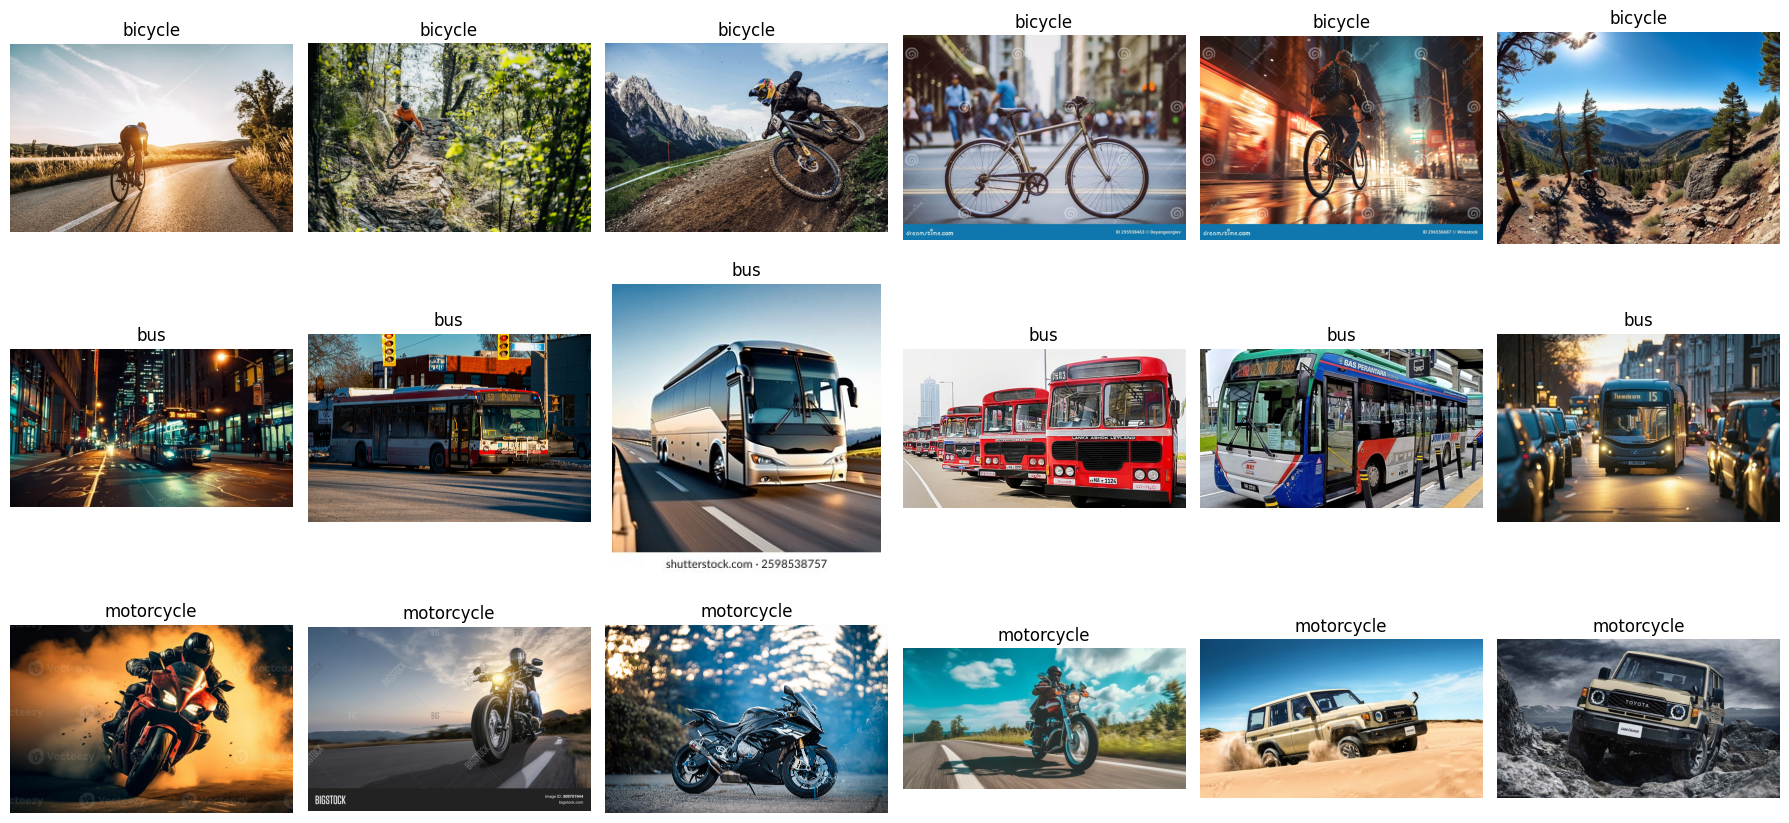

In [9]:
def show_random_images(root, n_per_class=6):
    root = Path(root)
    class_dirs = [p for p in sorted(root.iterdir()) if p.is_dir()]
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    if len(class_dirs) == 1:
        axes = np.expand_dims(axes, 0)
    for row, class_dir in enumerate(class_dirs):
        files = list(class_dir.glob("*.jpg"))
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                img = Image.open(chosen[col])
                ax.imshow(img)
                ax.set_title(class_dir.name)
            ax.axis("off")
    plt.tight_layout()

show_random_images(RAW_DIR)

### Checkpoint del dataset

Antes de continuar, asegúrate de que:

- cada carpeta contiene imágenes realmente asociadas a su clase;
- no predominan logos, dibujos o texto que revele la etiqueta;
- no hay una diferencia de fondo/estilo demasiado obvia entre clases;
- el número de imágenes por clase es razonablemente balanceado.

Registra aquí el número de imágenes eliminadas y el problema de calidad más frecuente.

### Registro del checkpoint del dataset

No eliminé imágenes. Detecté problemas de calidad que dejo como limitación del dataset: camionetas 4x4 en motorcycle, marcas de agua y texto (por ejemplo, Shutterstock) y fotos que parecen generadas por IA. El problema más visible en la muestra revisada fue la clase equivocada. Las clases quedaron balanceadas: 101 imágenes de bicycle, 98 de bus y 99 de motorcycle.

# 4. Separar train, validation y test — EN CLASE

> **Concepto clave — tres conjuntos, tres funciones**
>
> - **Train:** se utiliza para actualizar los pesos del modelo.
> - **Validation:** se utiliza durante el desarrollo para decidir épocas, `learning_rate`, número de capas a descongelar, etc.
> - **Test:** se reserva para medir el rendimiento final. No debe guiar las decisiones de entrenamiento.

Usaremos **70 % entrenamiento, 15 % validación y 15 % prueba**.

In [10]:
SPLIT_DIR = Path("dataset")

def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    source_root = Path(source_root)
    destination_root = Path(destination_root)
    if destination_root.exists():
        shutil.rmtree(destination_root)
    rng = random.Random(seed)

    for class_dir in sorted(source_root.iterdir()):
        if not class_dir.is_dir():
            continue
        files = list(class_dir.glob("*.jpg"))
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        splits = {
            "train": files[:n_train],
            "validation": files[n_train:n_train+n_val],
            "test": files[n_train+n_val:],
        }
        for split_name, split_files in splits.items():
            target = destination_root / split_name / class_dir.name
            target.mkdir(parents=True, exist_ok=True)
            for src in split_files:
                shutil.copy2(src, target / src.name)

split_dataset(RAW_DIR, SPLIT_DIR)
for split in ["train", "validation", "test"]:
    print(split, count_images(SPLIT_DIR / split))

train {'bicycle': 70, 'bus': 68, 'motorcycle': 69}
validation {'bicycle': 15, 'bus': 14, 'motorcycle': 14}
test {'bicycle': 16, 'bus': 16, 'motorcycle': 16}


### Comprobación conceptual

Explica brevemente: ¿por qué usar repetidamente el conjunto de prueba para escoger épocas, `learning_rate` o capas a descongelar termina contaminando nuestra estimación de desempeño?

**Respuesta:** porque el conjunto de prueba existe para dar una estimación **honesta** de cómo se comportará el modelo con datos que nunca influyeron en ninguna decisión. Si lo usamos repetidamente para escoger épocas, `learning_rate` o cuántas capas descongelar, estamos **ajustando esas decisiones a los datos de test** (nos quedamos con la configuración que mejor les va, parte por azar). Entonces la información de test se filtra al proceso de desarrollo, la métrica final queda **optimista** y ya no representa el desempeño real con datos nuevos. Por eso las decisiones se toman con *validation* y *test* se abre una sola vez al final.

# 5. Construir los datasets de Keras — EN CLASE

`image_dataset_from_directory()` construye un `tf.data.Dataset` usando el nombre de las carpetas como clases.

Observa que:

- `train` se mezcla (`shuffle=True`);
- `validation` y `test` mantienen un orden estable;
- todas las imágenes se redimensionan a `224×224` para EfficientNetB0.

In [11]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print(class_names)

Found 207 files belonging to 3 classes.
Found 43 files belonging to 3 classes.
Found 48 files belonging to 3 classes.
['bicycle', 'bus', 'motorcycle']


# 6. Primer modelo: transfer learning — EN CLASE

Usaremos **EfficientNetB0** preentrenada en ImageNet. Primero congelaremos completamente la red base y entrenaremos solo una nueva cabeza de clasificación.

> **Concepto clave — Data augmentation**
>
> `RandomFlip`, `RandomRotation` y `RandomZoom` generan variaciones plausibles durante el entrenamiento. No crean información nueva, pero ayudan a que el modelo dependa menos de detalles accidentales de las imágenes descargadas.

> **Concepto clave — GlobalAveragePooling2D**
>
> En lugar de aplanar todos los mapas de características con `Flatten`, `GlobalAveragePooling2D` resume cada canal en un solo valor. Así reducimos mucho el número de parámetros de la cabeza de clasificación.

In [12]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## TODO 3 — EN CLASE: entrena la cabeza de clasificación

La base EfficientNet está congelada. Tu trabajo es configurar y entrenar la nueva cabeza.

> **Concepto clave — EarlyStopping**
>
> `EarlyStopping` detiene el entrenamiento cuando `val_loss` deja de mejorar. Con `restore_best_weights=True`, Keras recupera los pesos de la mejor época observada en validación.

Antes de ejecutar, escribe una predicción corta:

- ¿esperas que `train_accuracy` suba rápidamente?
- ¿qué señal en las curvas indicaría overfitting?

Completa únicamente los espacios `TODO` del código siguiente.

**Predicción antes de ejecutar:**

- **¿`train_accuracy` sube rápidamente?** Sí, esperamos que suba muy rápido (en pocas épocas): la base EfficientNetB0 ya extrae características muy informativas de ImageNet, y solo se entrena una cabeza pequeña (`Dense` de 3 salidas, 3 843 parámetros).
- **¿Qué señal indicaría overfitting?** Que `train_accuracy` siga mejorando mientras `val_accuracy` se estanca o empeora y `val_loss` empieza a **subir** (brecha creciente entre las curvas de train y validación).

In [13]:
# TODO 3 — EN CLASE: completa la configuración de entrenamiento

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),  # 1e-3
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],                                      # "accuracy"
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",                  # "val_loss"
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping],
)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 19s 762ms/step - accuracy: 0.3575 - loss: 1.1548 - val_accuracy: 0.7907 - val_loss: 0.8243
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 415ms/step - accuracy: 0.8019 - loss: 0.7180 - val_accuracy: 0.9070 - val_loss: 0.5070
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 409ms/step - accuracy: 0.8889 - loss: 0.4903 - val_accuracy: 0.9767 - val_loss: 0.3416
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 384ms/step - accuracy: 0.9372 - loss: 0.3400 - val_accuracy: 0.9535 - val_loss: 0.2550
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 405ms/step - accuracy: 0.8986 - loss: 0.3084 - val_accuracy: 0.9535 - val_loss: 0.2051
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 378ms/step - accuracy: 0.9614 - loss: 0.2091 - val_accuracy: 0.9535 - val_loss: 0.1753
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 439ms/step - accuracy: 0.9372 - loss: 0.2018 - val_accuracy: 0.9767 - val_loss: 0.1528
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 405ms/step - accuracy: 0.9614 - loss: 0.2011 - val_accuracy: 0.9767 - val_loss

### Curvas de aprendizaje — EN CLASE si el tiempo lo permite

Grafica `accuracy`, `val_accuracy`, `loss` y `val_loss`.

Si el tiempo de clase termina antes, **puedes completar estas curvas en casa**.  
Lo obligatorio antes de salir es haber entrenado el primer modelo y tener sus métricas de entrenamiento/validación.

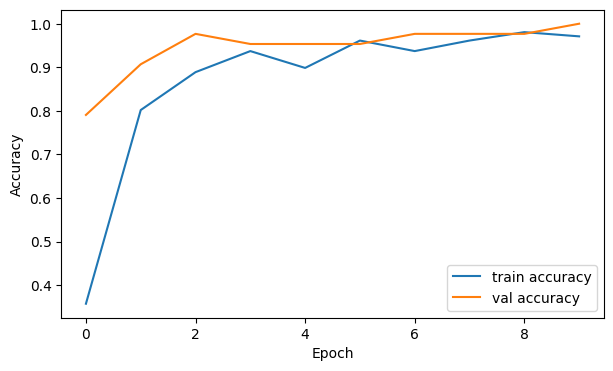

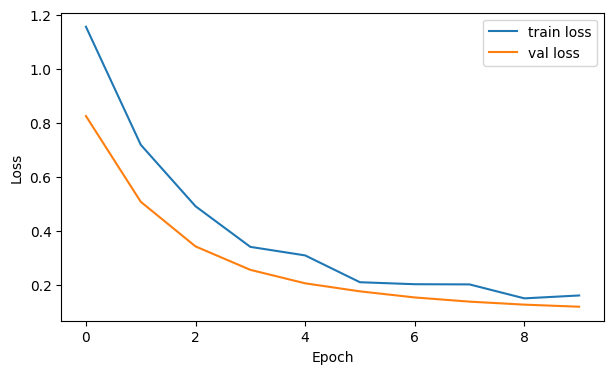

In [14]:
# Completa las cuatro curvas usando el objeto history
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# PUNTO DE CONTROL — FIN DEL TRABAJO EN CLASE

Antes de continuar, verifica que tu equipo tenga:

- [ ] 3 clases definidas;
- [ ] términos de búsqueda documentados;
- [ ] imágenes descargadas;
- [ ] dataset inspeccionado y parcialmente limpiado;
- [ ] separación `train / validation / test`;
- [ ] EfficientNetB0 con pesos de ImageNet;
- [ ] backbone congelado;
- [ ] nueva cabeza de clasificación;
- [ ] al menos un entrenamiento completado;
- [ ] `accuracy` y `val_accuracy` reportadas.

## Hasta aquí llega el trabajo de clase.

**No uses todavía el conjunto de test para tomar decisiones.**

---

# PARTE B — TRABAJO EN CASA

A partir de este punto debes completar el análisis de manera autónoma.

Ahora sí vas a:

1. evaluar el modelo en `test`;
2. estudiar la matriz de confusión y métricas por clase;
3. realizar fine-tuning;
4. comparar el modelo congelado contra el modelo ajustado;
5. analizar errores;
6. escribir las conclusiones.

# 7. Evaluación del primer modelo — EN CASA

Ahora sí utilizaremos el conjunto de prueba.

> **Concepto clave — No todo es accuracy**
>
> - **Precision:** de las imágenes que el modelo predijo como una clase, ¿cuántas eran correctas?
> - **Recall:** de las imágenes que realmente pertenecían a una clase, ¿cuántas encontró?
> - **F1:** combina precision y recall.
> - **Matriz de confusión:** muestra qué clases se están confundiendo entre sí.

Guarda esta evaluación: será nuestra línea base antes del fine-tuning.

In [15]:
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")

Test accuracy antes del fine-tuning: 1.0000


              precision    recall  f1-score   support

     bicycle      1.000     1.000     1.000        16
         bus      1.000     1.000     1.000        16
  motorcycle      1.000     1.000     1.000        16

    accuracy                          1.000        48
   macro avg      1.000     1.000     1.000        48
weighted avg      1.000     1.000     1.000        48



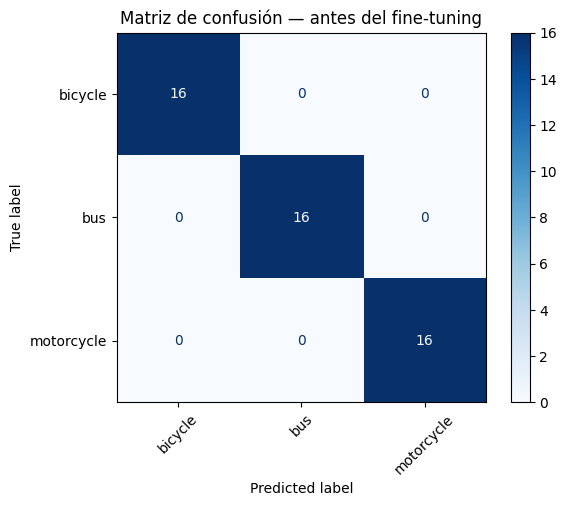

In [16]:
def get_predictions(model, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()

## TODO 4 — EN CASA: interpreta la evaluación

Utilizando `classification_report` y la matriz de confusión, responde:

1. ¿Cuál clase obtuvo mejores resultados?
2. ¿Cuál fue la principal confusión?
3. ¿La accuracy global oculta algún problema por clase?
4. ¿Qué cambiarías primero en el **dataset** antes de cambiar el modelo?

### Respuestas al TODO 4 — interpretación de la evaluación

1. Mejor clase: las tres clases obtuvieron precision, recall y F1 de 1.000 (empate);
   por ejemplo, motorcycle clasificó correctamente sus 16 imágenes de test.
2. Principal confusión: no hubo ninguna; la matriz de confusión tiene ceros fuera de la diagonal.
3. ¿La accuracy global esconde algo? No: el recall de cada clase también es 1.0. Aun así,
   un 100 % en un test pequeño (16 imágenes por clase, 48 en total) no prueba que el modelo sea perfecto:
   solo indica que esta tarea es fácil para EfficientNetB0, o que puede haber casi-duplicados
   entre train y test que inflan el resultado.
4. Lo primero que cambiaría es el dataset: quitar las imágenes mal etiquetadas (camionetas 4x4
   en motorcycle), las de marca de agua y las generadas por IA, buscar casi-duplicados antes
   del split y añadir fotos más variadas o una clase más difícil para que el test sea más exigente.

# 8. Fine-tuning — EN CASA

Ahora permitiremos que una pequeña parte de EfficientNet se adapte al nuevo problema.

> **Concepto clave — Fine-tuning**
>
> En la fase anterior, los pesos del backbone no cambiaron. Ahora descongelaremos únicamente una parte final del modelo y la actualizaremos con un **learning rate mucho menor**.

> **Concepto clave — Batch Normalization**
>
> EfficientNet contiene capas `BatchNormalization`, que mantienen estadísticas internas aprendidas durante el entrenamiento. En datasets pequeños conviene mantenerlas congeladas durante fine-tuning para evitar actualizaciones inestables de esas estadísticas.

Después de cambiar qué capas son entrenables, es necesario **recompilar** el modelo.

In [17]:
base_model.trainable = True

# TODO 5 — Decide cuántas capas finales adaptar.
# Empieza con ~20. Puedes justificar otro valor usando validation.
N_UNFROZEN = 20

for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False

# Mantener Batch Normalization congelado.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in base_model.layers),
    "/",
    len(base_model.layers),
)

Capas entrenables de la base: 15 / 238


## TODO 5 — EN CASA: realiza fine-tuning

Recompila y continúa el entrenamiento.

Usa como punto de partida:

- `Adam(learning_rate=1e-5)`;
- `SparseCategoricalCrossentropy`;
- `accuracy`;
- entre **3 y 8 épocas** adicionales;
- `EarlyStopping` sobre `val_loss`.

Tu decisión principal aquí es **cuántas capas descongelar**. Justifícala usando el desempeño de validación, no el conjunto de prueba.

In [18]:
# TODO 5 — EN CASA: completa el fine-tuning

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  # 1e-5
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=6,  # entre 3 y 8
    callbacks=[early_stopping_ft],
)

Epoch 1/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 15s 827ms/step - accuracy: 0.9758 - loss: 0.1424 - val_accuracy: 1.0000 - val_loss: 0.1125
Epoch 2/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 427ms/step - accuracy: 0.9855 - loss: 0.1235 - val_accuracy: 1.0000 - val_loss: 0.1068
Epoch 3/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 385ms/step - accuracy: 0.9517 - loss: 0.1554 - val_accuracy: 1.0000 - val_loss: 0.1024
Epoch 4/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 410ms/step - accuracy: 0.9807 - loss: 0.1285 - val_accuracy: 1.0000 - val_loss: 0.0984
Epoch 5/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 410ms/step - accuracy: 0.9614 - loss: 0.1374 - val_accuracy: 1.0000 - val_loss: 0.0946
Epoch 6/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 404ms/step - accuracy: 0.9710 - loss: 0.1291 - val_accuracy: 1.0000 - val_loss: 0.0915


### Justificación de N_UNFROZEN (TODO 5)

Usé N_UNFROZEN = 20, lr = 1e-5 y 6 épocas. En validación, el val_accuracy ya era 1.0000
desde la fase congelada, así que no sirve para comparar. Lo que sí mejoró fue el val_loss,
que bajó de 0.1125 a 0.0915 durante el fine-tuning, sin señales de sobreajuste. Por eso
mantuve 20 capas descongeladas. Las capas BatchNormalization siguen congeladas a propósito,
porque con un dataset pequeño sus estadísticas internas se vuelven inestables.


# 9. Comparación final — EN CASA

Compara el desempeño del mismo sistema **antes y después** del fine-tuning.

Una mejora pequeña también puede ser válida. Si el resultado empeora, no significa que el experimento “salió mal”: debes interpretar por qué pudo ocurrir.

In [19]:
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")

Antes del fine-tuning  : 1.0000
Después del fine-tuning: 1.0000
Diferencia              : +0.0000


              precision    recall  f1-score   support

     bicycle      1.000     1.000     1.000        16
         bus      1.000     1.000     1.000        16
  motorcycle      1.000     1.000     1.000        16

    accuracy                          1.000        48
   macro avg      1.000     1.000     1.000        48
weighted avg      1.000     1.000     1.000        48



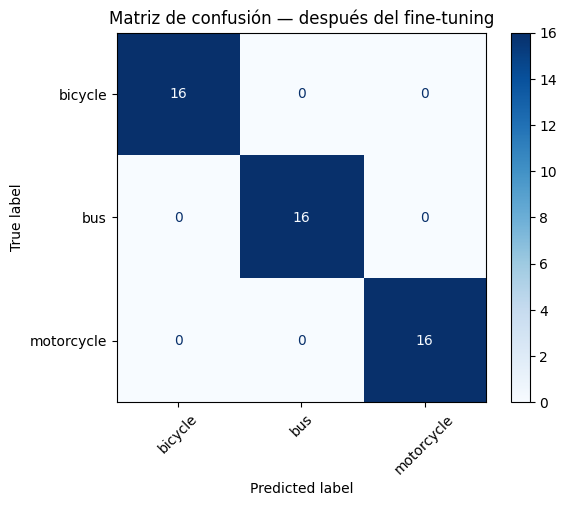

In [20]:
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names, digits=3))
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()

### Comparación antes vs. después del fine-tuning

- Accuracy en test: antes 1.0000, después 1.0000, diferencia +0.0000.
- Por clase: bicycle, bus y motorcycle tienen precision, recall y F1 de 1.000 (16 imágenes de test
  por clase); ninguna mejoró ni empeoró.
- Interpretación: el accuracy ya estaba en el máximo con la base congelada, así que el fine-tuning
  no tenía margen para mejorarlo. Lo único que se movió fue el val_loss (0.1125 → 0.0915). Con solo
  48 imágenes de test y una tarea fácil para EfficientNetB0, esta métrica no distingue entre ambos modelos.

# 10. Analiza los errores — EN CASA

Una métrica no explica por qué falla un modelo. Debes inspeccionar ejemplos clasificados incorrectamente.

In [21]:
def show_mistakes(dataset, model, class_names, max_images=12):
    mistakes = []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        preds = probs.argmax(axis=1)
        for image, true_label, pred_label, prob in zip(images.numpy(), labels.numpy(), preds, probs):
            if true_label != pred_label:
                mistakes.append((image.astype("uint8"), int(true_label), int(pred_label), float(prob[pred_label])))
    random.shuffle(mistakes)
    mistakes = mistakes[:max_images]
    if not mistakes:
        print("No se encontraron errores en este conjunto.")
        return
    cols = 4
    rows = int(np.ceil(len(mistakes)/cols))
    plt.figure(figsize=(16, 4*rows))
    for i, (image, true_label, pred_label, confidence) in enumerate(mistakes):
        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(image)
        ax.set_title(f"Real: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()

show_mistakes(test_ds, model, class_names)

No se encontraron errores en este conjunto.


## TODO 6 — EN CASA: análisis de errores y conclusiones

Selecciona al menos **5 errores** del modelo y analiza su causa probable.

| Imagen/error | Clase real | Predicción | Causa probable | ¿Cómo lo mejorarías? |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |
| 5 | | | | |

Posibles causas: imagen ambigua, etiqueta incorrecta, objeto pequeño, oclusión, fondo engañoso, clase visualmente similar, mala calidad, sesgo del dataset o error razonable del modelo.

Después, escribe una conclusión breve respondiendo:

1. ¿Qué aprendiste al construir el dataset?
2. ¿Cuál fue el principal problema de calidad?
3. ¿Cuánto cambió el desempeño después del fine-tuning?
4. ¿El fine-tuning ayudó? ¿Por qué crees que sí o no?
5. ¿Qué mejorarías primero: datos, entrenamiento o arquitectura?

### TODO 6 — Tabla de errores y conclusiones

**Nota importante:** el modelo no cometió ningún error en el conjunto de prueba (48 de 48 aciertos, antes y después del fine-tuning; `show_mistakes` imprimió «No se encontraron errores»). Por eso no hay 5 errores reales del modelo que analizar. En su lugar, la tabla recoge 5 **casos de calidad de datos** que observé al inspeccionar una muestra de 18 imágenes del dataset, y que son los que podrían producir errores o inflar los resultados.

| Imagen/error | Clase real | Predicción | Causa probable | ¿Cómo lo mejorarías? |
|---|---|---|---|---|
| 1. Camioneta 4x4 en la carpeta `motorcycle` | Camioneta (etiqueta: motorcycle) | No hubo error en test | Etiqueta incorrecta: el buscador devolvió un vehículo todoterreno | Revisión manual y eliminar la imagen |
| 2. Segunda camioneta 4x4 en `motorcycle` | Camioneta (etiqueta: motorcycle) | No hubo error en test | Etiqueta incorrecta; se repite el patrón (2 de las 6 imágenes de motorcycle visibles en la muestra) | Términos de búsqueda más específicos («motorcycle rider», sin «off-road»), y limpiar la clase |
| 3. Bus con marca de agua de Shutterstock | Bus | No hubo error en test | Sesgo del dataset: la marca de agua puede servir de «atajo» en lugar del vehículo | Recortar la marca o eliminar la imagen |
| 4. Bicicleta de ciudad con marca de agua | Bicycle | No hubo error en test | Mismo sesgo: texto/marca de agua en la imagen | Quitar o recortar imágenes con marca de agua |
| 5. Bicicleta casi invisible en un paisaje de montaña | Bicycle | No hubo error en test | Objeto muy pequeño y fondo dominante; la imagen aporta poco sobre la clase | Descartarla o recortar alrededor de la bicicleta |

**Conclusiones**

1. **¿Qué aprendí al construir el dataset?** Que la calidad de los datos pesa tanto como el modelo: un buscador de imágenes mezcla etiquetas equivocadas, marcas de agua e imágenes generadas por IA, y hay que revisarlo a mano antes de entrenar. Construí 298 imágenes (101 bicycle, 99 motorcycle, 98 bus), divididas en 207 de entrenamiento, 43 de validación y 48 de prueba.
2. **¿Cuál fue el principal problema de calidad?** La clase equivocada (camionetas 4x4 dentro de `motorcycle`), seguida de las marcas de agua y de las imágenes que parecen generadas por IA.
3. **¿Cuánto cambió el desempeño después del fine-tuning?** El accuracy en test no cambió: 1.0000 antes y 1.0000 después (diferencia +0.0000), con precision, recall y F1 de 1.000 en las tres clases. En validación, el `val_accuracy` fue 1.0000 en todas las épocas y el `val_loss` bajó de 0.1125 a 0.0915 durante el fine-tuning.
4. **¿El fine-tuning ayudó?** No en accuracy, porque ya estaba en el máximo con la base congelada: el backbone preentrenado en ImageNet ya separaba muy bien bicicletas, motos y buses. Solo mejoró levemente la pérdida de validación. Con un dataset pequeño y una tarea fácil, el ajuste fino no tenía margen para mejorar la métrica.
5. **¿Qué mejoraría primero?** Los **datos**: limpiar etiquetas equivocadas, quitar marcas de agua y detectar casi-duplicados antes de hacer el split (pueden estar repartidos entre train y test e inflar el 100 %). Además, un test de solo 48 imágenes y tres clases tan distintas es poco exigente; agregaría una cuarta clase parecida (por ejemplo, scooter) para tener un test más informativo.

# Extensión opcional — Prueba con una imagen externa

Busca una imagen que **no esté en tu dataset** y prueba el modelo. Esta parte no cuenta como un TODO principal, pero sirve como comprobación cualitativa de generalización.

In [22]:
# OPCIONAL
# EXTERNAL_IMAGE_URL = "https://..."
# response = requests.get(EXTERNAL_IMAGE_URL, timeout=10)
# response.raise_for_status()
# img = Image.open(io.BytesIO(response.content)).convert("RGB")
# img_resized = img.resize(IMG_SIZE)
# x = np.array(img_resized, dtype="float32")[None, ...]
# p = model.predict(x, verbose=0)[0]
# plt.imshow(img)
# plt.axis("off")
# plt.title(f"{class_names[p.argmax()]} — confianza {p.max():.2f}")
# plt.show()

# 🏠 Cierre conceptual — ENTREGA

Como parte del **TODO 6**, explica con tus propias palabras la diferencia entre:

- **feature extraction / transfer learning con base congelada**;
- **fine-tuning**;
- **entrenar una CNN desde cero**.

No describas solo el código. Explica **qué parámetros se están aprendiendo y de dónde viene el conocimiento inicial**.

**Respuesta — diferencia entre los tres enfoques**

| Enfoque | ¿Qué parámetros se aprenden? | ¿De dónde viene el conocimiento inicial? |
|---|---|---|
| **Feature extraction (transfer learning con base congelada)** | Solo la **nueva cabeza** (`GlobalAveragePooling2D` no tiene pesos; `Dense(3)` sobre 1 280 características = 1 280·3 + 3 = **3 843 parámetros**). Los ≈ 4 millones de parámetros de EfficientNetB0 no cambian. | De los **pesos preentrenados en ImageNet**: el backbone ya aprendió a detectar bordes, texturas, partes y objetos, y se usa como extractor de características fijo. |
| **Fine-tuning** | La cabeza **y** las últimas capas del backbone que se descongelan (aquí 20; la `BatchNormalization` sigue congelada), con un learning rate muy pequeño (1e-5) para ajustarlas sin destruir lo aprendido. | De ImageNet **más** lo que ya aprendió la cabeza en la fase anterior; el fine-tuning solo **adapta** las características de alto nivel al dominio nuevo (bicicletas, motos, buses). |
| **CNN desde cero** | **Todos** los parámetros, inicializados al azar. | De ninguna parte: el único conocimiento es el de **tus propias imágenes**. Necesita muchísimos más datos y cómputo; con ≈ 100 imágenes por clase se sobreajustaría con facilidad. |

En resumen: transfer learning reutiliza conocimiento visual general de ImageNet y entrena poco (rápido, funciona con pocos datos); el fine-tuning añade una adaptación fina de unas pocas capas; y desde cero lo debe aprender todo, por lo que es el menos práctico con un dataset pequeño como el nuestro.

# Reto opcional

Elige **uno**:

**A. Más datos:** duplica el número de imágenes manteniendo el modelo igual.  
**B. Otro backbone:** prueba MobileNetV3, ResNet50 o EfficientNetV2B0.  
**C. Dataset difícil:** agrega una cuarta clase visualmente parecida.  
**D. Ablation:** entrena sin `data_augmentation` y compara.

Cambia **una sola variable a la vez**.

# ✅ Checklist de entrega

Antes de entregar verifica:

### Evidencia del trabajo en clase
- [x] Problema y clases definidos.
- [x] Dataset construido y revisado.
- [x] Train / validation / test creados.
- [x] Primer modelo con backbone congelado entrenado.

### Trabajo en casa
- [x] Evaluación sobre test.
- [x] Matriz de confusión.
- [x] Precision / recall / F1 interpretados.
- [x] Fine-tuning ejecutado.
- [x] Comparación antes vs. después del fine-tuning.
- [ ] Al menos 5 errores analizados. *(El modelo no cometió errores en test; en el TODO 6 se analizaron 5 casos de calidad de datos.)*
- [x] Conclusión final escrita.

### Opcional
- [ ] Imagen externa.
- [ ] Experimento adicional / reto.

# Rúbrica sugerida

| Componente | Peso |
|---|---:|
| TODO 1 — Problema y estrategia de búsqueda | 10% |
| TODO 2 — Construcción, inspección y limpieza del dataset | 20% |
| Split y pipeline de datos | 10% |
| TODO 3 — Transfer learning + curvas | 20% |
| TODO 4 — Evaluación e interpretación | 10% |
| TODO 5 — Fine-tuning y comparación | 15% |
| TODO 6 — Análisis de errores + conclusión conceptual | 15% |
| **Total** | **100%** |